# **Лабораторна робота 5**
**Обробка текстових даних, рядкові методи та регулярні вирази**

**Мета:** Опанувати практичні навички алгоритмічної обробки, валідації, нормалізації та структурування текстової інформації мовою Python. Навчитися застосовувати базові та розширені методи рядкового типу str для очищення й токенізації даних, проектувати шаблони динамічного форматування за допомогою сучасних f-рядків (f-strings) із точним позиціонуванням ширини полів та числових специфікаторів, а також освоїти математичний апарат регулярних виразів (модуль re) для синтаксичного аналізу, валідації та вилучення структурованих параметрів із журналів подій і конфігураційних файлів комп'ютерних систем.


**Зроблено:** П'ятибрат Дмитро

**Варіант:** 16

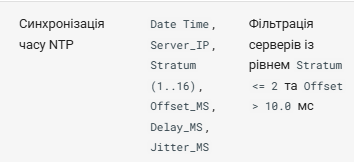

In [1]:
import re

# Скомпільований регулярний вираз з іменованими групами (?P<name>...)
NTP_LOG_PATTERN = re.compile(
    r"^(?P<date>\d{4}-\d{2}-\d{2})\s+"
    r"(?P<time>\d{2}:\d{2}:\d{2})\s+"
    r"(?P<server_ip>(?:\d{1,3}\.){3}\d{1,3})\s+"
    r"(?P<stratum>\d+)\s+"
    r"(?P<offset_ms>[-+]?\d+(?:\.\d+)?)\s+"
    r"(?P<delay_ms>\d+(?:\.\d+)?)\s+"
    r"(?P<jitter_ms>\d+(?:\.\d+)?)$"
)

# Перевіряє коректність октетів IP-адреси (0-255).
def validate_ip(ip_str: str) -> bool:
    parts = ip_str.split(".")
    if len(parts) != 4:
        return False
    for part in parts:
        try:
            val = int(part)
            if not 0 <= val <= 255:
                return False
        except ValueError:
            return False
    return True

# Очищує вхідний рядок від зайвих пробілів та некоректних керівних символів.
def clean_line(line: str) -> str:
    # Видалення невидимих/керівних символів, крім базових пробільних
    sanitized = re.sub(r"[^\x20-\x7E]", "", line)
    # Нормалізація повторюваних пробілів до одного та trim
    return re.sub(r"\s+", " ", sanitized).strip()


def parse_and_process_ntp_logs(raw_lines: list[str]):
    records = []

    for raw in raw_lines:
        line = clean_line(raw)
        if not line:
            continue

        match = NTP_LOG_PATTERN.match(line)
        if not match:
            continue

        data = match.groupdict()

        # Валідація числових та мережевих діапазонів
        if not validate_ip(data["server_ip"]):
            continue

        stratum = int(data["stratum"])
        if not (1 <= stratum <= 16):
            continue

        offset = float(data["offset_ms"])
        delay = float(data["delay_ms"])
        jitter = float(data["jitter_ms"])

        # Критерій варіанта: Stratum <= 2 та Offset > 10.0 мс
        is_matched = (stratum <= 2) and (offset > 10.0)

        records.append({
            "datetime": f"{data['date']} {data['time']}",
            "ip": data["server_ip"],
            "stratum": stratum,
            "offset": offset,
            "delay": delay,
            "jitter": jitter,
            "matched": is_matched
        })

    # Виведення діагностичної таблиці за допомогою f-рядків
    print("\n" + "=" * 90)
    print(f"{'ДІАГНОСТИЧНА ТАБЛИЦЯ NTP ПАКЕТІВ':^90}")
    print("=" * 90)
    print(
        f"{'Дата і час':<20} | "
        f"{'Server IP':<16} | "
        f"{'Stratum':>7} | "
        f"{'Offset (мс)':>11} | "
        f"{'Delay (мс)':>10} | "
        f"{'Jitter (мс)':>11} | "
        f"{'Фільтр':^8}"
    )
    print("-" * 90)

    filtered_records = []
    for r in records:
        match_str = "Так" if r["matched"] else "Ні"
        if r["matched"]:
            filtered_records.append(r)

        print(
            f"{r['datetime']:<20} | "
            f"{r['ip']:<16} | "
            f"{r['stratum']:>7d} | "
            f"{r['offset']:>11.3f} | "
            f"{r['delay']:>10.3f} | "
            f"{r['jitter']:>11.3f} | "
            f"{match_str:^8}"
        )
    print("=" * 90)

    # Підрахунок агрегованої статистики
    total_count = len(records)
    filtered_count = len(filtered_records)

    if filtered_count > 0:
        avg_offset = sum(r["offset"] for r in filtered_records) / filtered_count
        max_offset = max(r["offset"] for r in filtered_records)
        avg_jitter = sum(r["jitter"] for r in filtered_records) / filtered_count
    else:
        avg_offset = max_offset = avg_jitter = 0.0

    print(f"\n{'ПІДСУМКОВА АГРЕГОВАНА СТАТИСТИКА':^45}")
    print("-" * 45)
    print(f"Оброблено валідних записів : {total_count}")
    print(f"Відфільтровано (Stratum<=2 & Offset>10) : {filtered_count}")
    print(f"Середній зсув (Offset) для фільтра      : {avg_offset:.3f} мс")
    print(f"Максимальний зсув (Max Offset)         : {max_offset:.3f} мс")
    print(f"Середній джитер (Avg Jitter)            : {avg_jitter:.3f} мс")
    print("-" * 45)


# Демонстрація виконання
if __name__ == "__main__":
    test_logs = [
        "  2026-10-10 14:02:11   192.168.1.10   1   14.250   5.120   0.450 \t",     # Проходить фільтр (stratum 1, offset > 10)
        "2026-10-10 14:02:12 172.16.0.5 2 11.800 12.300 1.200",                    # Проходить фільтр (stratum 2, offset > 10)
        "2026-10-10 14:02:13 10.0.0.1 2 4.100 8.500 0.800",                       # Не проходить (offset <= 10)
        "2026-10-10 14:02:14 192.168.1.20 3 18.500 20.100 2.400",                 # Не проходить (stratum 3 > 2)
        "2026-10-10 14:02:15 999.168.1.1 1 15.000 4.000 0.500",                   # Некоректний IP (відсіюється)
        "2026-10-10 14:02:16 192.168.1.30 18 12.000 4.000 0.500",                  # Некоректний Stratum > 16 (відсіюється)
    ]

    parse_and_process_ntp_logs(test_logs)


                             ДІАГНОСТИЧНА ТАБЛИЦЯ NTP ПАКЕТІВ                             
Дата і час           | Server IP        | Stratum | Offset (мс) | Delay (мс) | Jitter (мс) |  Фільтр 
------------------------------------------------------------------------------------------
2026-10-10 14:02:11  | 192.168.1.10     |       1 |      14.250 |      5.120 |       0.450 |   Так   
2026-10-10 14:02:12  | 172.16.0.5       |       2 |      11.800 |     12.300 |       1.200 |   Так   
2026-10-10 14:02:13  | 10.0.0.1         |       2 |       4.100 |      8.500 |       0.800 |    Ні   
2026-10-10 14:02:14  | 192.168.1.20     |       3 |      18.500 |     20.100 |       2.400 |    Ні   

      ПІДСУМКОВА АГРЕГОВАНА СТАТИСТИКА       
---------------------------------------------
Оброблено валідних записів : 4
Відфільтровано (Stratum<=2 & Offset>10) : 2
Середній зсув (Offset) для фільтра      : 13.025 мс
Максимальний зсув (Max Offset)         : 14.250 мс
Середній джитер (Avg Jitter)        

**Контрольні запитання**

1. Модель рядків PEP 393 у CPythonCPython адаптує ширину символу під найбільший кодовий пункт:
Latin-1 (1 байт): символи $U+0000 \dots U+00FF$ (включаючи ASCII).
UCS-2 (2 байти): символи $U+0100 \dots U+FFFF$.
UCS-4 (4 байти): символи вище $U+10000$ (емодзі тощо).
Усі символи всередині одного масиву PyUnicodeObject мають однакову фіксовану ширину для доступу за $O(1)$. Додавання хоча б одного символу кирилиці (кодовий пункт $> 255$) вимагає підвищення розрядності кожного символу до 2 байтів, інакше змішаний масив втратив би адресацію за індексом без сканування.
2. Неефективність += проти str.join()
+= ($O(N^2)$): рядки в Python незмінні (immutable). Кожна операція виділяє новий буфер у пам'яті й копіює туди акумульований результат, що на $k$-му кроці вимагає копіювання пропорційно поточній довжині: $\sum_{k=1}^N k = O(N^2)$.
str.join() ($O(N)$): виконує два проходи — спочатку підсумовує довжини всіх рядків і роздільників, одразу виділяє один блок пам'яті точного розміру, а другим проходом через memcpy копіює дані.
3. re.match(): шукає збіг виключно на початку рядка.
re.search(): шукає перший збіг у довільному місці всього рядка.
re.finditer(): ліниво повертає генератор об'єктів Match для всіх збігів.
Коли обирати finditer замість findall: обробка великих файлів або логів, коли не можна завантажувати всі збіги в пам'ять одразу (економія RAM), або коли потрібні метадані збігів (позиції start(), end(), групи).
4. Катастрофічне повернення та ліниві квантифікатори
Catastrophic Backtracking: виникає в жадібних NFA-рушіях при вкладених або перекритих квантифікаторах (наприклад, $(a+)$+$). За відсутності повного збігу рушій перебирає всі експоненційні комбінації шляхів повернення (O(2^n)), блокуючи потік.
Запобігання: використання лінивих квантифікаторів (+?, *?) змушує рушій брати мінімальну кількість символів і перевіряти наступний токен, уникаючи захоплення всього рядка та надмірного відкату.
5. Іменовані групи (?P<name>pattern)
Синтаксис: r"(?P<user>\w+)@(?P<domain>\w+\.\w+)"
Призначення: дає групам читабельні ідентифікатори замість числових індексів, запобігаючи помилкам при зміні структури шаблону.
Отримання словника: виклик методу .groupdict() у знайденого об'єкта Match:
re.search(r"(?P<user>\w+)@(?P<domain>\w+\.\w+)", text)
data = m.groupdict()  # {'user': '...', 'domain': '...'}
6. Переваги f-рядків на рівні PVM-опкодів
str.format() та %: викликають опкоди пошуку атрибута LOAD_METHOD, аргументів CALL_METHOD / BINARY_MODULO, а парсинг рядка формату відбувається динамічно в рантаймі.
f-рядки: транслюються компілятором безпосередньо у спеціалізовані опкоди (FORMAT_VALUE, BUILD_STRING). Парсинг шаблону відбувається на етапі компіляції AST, а віртуальна машина просто конкатенує вже підготовлені значення в пам'яті C без накладних викликів функцій Python.